# 🏀 NBA Salary Predictor — Rede Neural v2

## Objetivo
Treinar uma Rede Neural com Keras/TensorFlow para prever
o salário anual de jogadores da NBA com base em suas
estatísticas de desempenho da temporada 2022-23.

## Contexto
Este notebook é uma evolução do modelo de Regressão Linear
desenvolvido no Módulo 1. A Rede Neural foi escolhida por:
- Capturar relações não lineares entre estatísticas e salário
- Arquiteturas mais flexívei em relação à modelos clássicos
- Padrão da indústria para problemas preditivos mais complexos

## Dataset
- NBA Players Stats and Salaries 2022-23
- 467 jogadores, 52 colunas originais
- Fonte: Kaggle

In [10]:
# ============================================================
# NBA Salary Predictor — Rede Neural
# Célula 1: Importações
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Fixando seeds para reprodutibilidade
import random
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)
os.environ["PYTHONHASHSEED"] = "42"

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Keras/TensorFlow
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Serialização
import joblib
import json
import os
from datetime import datetime

# Configurações
import warnings
warnings.filterwarnings("ignore")
tf.random.set_seed(42)
np.random.seed(42)

print(f"✅ TensorFlow versão: {tf.__version__}")
print(f"✅ Keras versão: {keras.__version__}")
print("✅ Bibliotecas importadas com sucesso!")

✅ TensorFlow versão: 2.21.0
✅ Keras versão: 3.13.2
✅ Bibliotecas importadas com sucesso!


## Fase 1: Carregamento dos Dados

Carregamos o mesmo dataset utilizado no Módulo 1 para
garantir uma comparação justa entre os modelos.
A variável alvo é `Salary` — valor numérico contínuo
em dólares representando o salário anual do jogador.

In [2]:
# ============================================================
# Célula 2: Carregar e Preparar os Dados
# ============================================================

# Carregar o dataset
df = pd.read_csv("nba_2022-23_all_stats_with_salary.csv")

print(f"✅ Dataset carregado com sucesso!")
print(f"   Linhas    : {df.shape[0]}")
print(f"   Colunas   : {df.shape[1]}")
print(f"\n📋 Primeiros registros:")
print(df.head())

✅ Dataset carregado com sucesso!
   Linhas    : 467
   Colunas   : 52

📋 Primeiros registros:
   Unnamed: 0        Player Name    Salary Position  Age     Team  GP  GS  \
0           0      Stephen Curry  48070014       PG   34      GSW  56  56   
1           1          John Wall  47345760       PG   32      LAC  34   3   
2           2  Russell Westbrook  47080179       PG   34  LAL/LAC  73  24   
3           3       LeBron James  44474988       PF   38      LAL  55  54   
4           4       Kevin Durant  44119845       PF   34  BRK/PHO  47  47   

     MP    FG  ...  TOV%  USG%  OWS  DWS   WS  WS/48  OBPM  DBPM  BPM  VORP  
0  34.7  10.0  ...  12.5  31.0  5.8  2.0  7.8  0.192   7.5   0.1  7.5   4.7  
1  22.2   4.1  ...  17.1  27.0 -0.4  0.7  0.3  0.020  -0.8  -0.4 -1.2   0.1  
2  29.1   5.9  ...  18.4  27.7 -0.6  2.6  1.9  0.044   0.3  -0.1  0.2   1.2  
3  35.5  11.1  ...  11.6  33.3  3.2  2.4  5.6  0.138   5.5   0.6  6.1   4.0  
4  35.6  10.3  ...  13.4  30.7  4.7  2.1  6.8  0.194 

In [4]:
from google.colab import files
arquivo = files.upload()

Saving nba_2022-23_all_stats_with_salary.csv to nba_2022-23_all_stats_with_salary (1).csv


## Fase 2: Pré-processamento com Pipeline Scikit-learn

Reutilizamos o mesmo pipeline de pré-processamento do
Módulo 1 para garantir consistência entre os modelos.

**Decisões técnicas:**
- **Pipeline Scikit-learn:** encadeia transformações evitando
  data leakage — o scaler é fitado apenas no treino
- **SimpleImputer (mediana):** distribuição assimétrica do
  salário torna a mediana mais robusta que a média
- **Winsorização IQR:** preserva todos os registros
  substituindo outliers pelo limite aceitável
- **Label Encoding:** transforma posições em números
  mantendo apenas 1 coluna
- **Remoção de multicolinearidade:** 12 colunas removidas
  com correlação acima de 0.85

In [5]:
# ============================================================
# Célula 3: Pipeline de Pré-processamento com Scikit-learn
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

def preprocessar_dados(df):
    """
    Aplica o pipeline de pré-processamento completo:
    1. Remove colunas desnecessárias
    2. Simplifica posições e times combinados
    3. Remove duplicatas
    4. Feature Engineering
    5. Label Encoding
    6. Remove multicolinearidade
    Retorna o DataFrame processado e o LabelEncoder
    """
    df = df.copy()

    # --------------------------------------------------------
    # Passo 1: Remover colunas desnecessárias
    # --------------------------------------------------------
    colunas_remover = [
        "Player Name", "Unnamed: 0",
        "FG%", "3P%", "FT%", "2P%", "eFG%",
        "FGA", "3PA", "FTA", "2PA",
        "BPM", "WS/48", "OBPM", "DBPM",
        "ORB", "DRB", "Total Minutes"
    ]
    df = df.drop(columns=colunas_remover)

    # --------------------------------------------------------
    # Passo 2: Simplificar posições e times combinados
    # --------------------------------------------------------
    df["Position"] = df["Position"].apply(
        lambda x: x.split("-")[0] if "-" in str(x) else x
    )
    df["Team"] = df["Team"].apply(
        lambda x: x.split("/")[0] if "/" in str(x) else x
    )

    # --------------------------------------------------------
    # Passo 3: Remover duplicatas
    # --------------------------------------------------------
    df = df.drop_duplicates()

    # --------------------------------------------------------
    # Passo 4: Feature Engineering
    # --------------------------------------------------------
    salary_por_time = df.groupby("Team")["Salary"].mean()
    p33 = salary_por_time.quantile(0.33)
    p66 = salary_por_time.quantile(0.66)

    def classificar_tier(team):
        salario_medio = salary_por_time[team]
        if salario_medio >= p66:
            return 3
        elif salario_medio >= p33:
            return 2
        else:
            return 1

    df["tier_time"] = df["Team"].apply(classificar_tier)
    df = df.drop(columns=["Team"])
    df["eficiencia"] = (
        df["PTS"] + df["AST"] +
        df["TRB"] + df["STL"] + df["BLK"]
    )

    # --------------------------------------------------------
    # Passo 5: Label Encoding
    # --------------------------------------------------------
    le = LabelEncoder()
    df["Position"] = le.fit_transform(df["Position"])

    # --------------------------------------------------------
    # Passo 6: Remover multicolinearidade
    # --------------------------------------------------------
    colunas_remover_corr = [
        "MP", "2P", "FT", "TOV", "FG",
        "DRB%", "OWS", "DWS", "AST%", "VORP"
    ]
    colunas_remover_corr = [c for c in colunas_remover_corr if c in df.columns]
    df = df.drop(columns=colunas_remover_corr)

    return df, le

# Aplicar pré-processamento
df_processado, le = preprocessar_dados(df)

# --------------------------------------------------------
# Separando X e y
# --------------------------------------------------------
X = df_processado.drop(columns=["Salary"])
y = df_processado["Salary"]

# --------------------------------------------------------
# Divisão 80/20 — treino e teste
# --------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# --------------------------------------------------------
# Pipeline de escalonamento
# Garante que o scaler é fitado apenas no treino
# e aplicado de forma consistente no teste
# --------------------------------------------------------
pipeline_scaler = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),  # trata NaN residuais
    ("scaler", StandardScaler())                     # padronização
])

X_train_scaled = pipeline_scaler.fit_transform(X_train)
X_test_scaled  = pipeline_scaler.transform(X_test)

# Divisão para validação durante treino da Rede Neural
X_train_real, X_val, y_train_real, y_val = train_test_split(
    X_train_scaled, y_train,
    test_size=0.2,
    random_state=42
)

print("=== PIPELINE APLICADO COM SUCESSO ===")
print("-" * 40)
print(f"  Total de registros : {len(X)}")
print(f"  Treino real        : {len(X_train_real)} registros")
print(f"  Validação          : {len(X_val)} registros")
print(f"  Teste              : {len(X_test_scaled)} registros")
print(f"  Features           : {X.shape[1]}")
print("-" * 40)

# Salvando o pipeline para usar na API
os.makedirs("models", exist_ok=True)
joblib.dump(pipeline_scaler, "models/pipeline_scaler.pkl")
print("\n✅ Pipeline salvo em models/pipeline_scaler.pkl")

=== PIPELINE APLICADO COM SUCESSO ===
----------------------------------------
  Total de registros : 467
  Treino real        : 298 registros
  Validação          : 75 registros
  Teste              : 94 registros
  Features           : 24
----------------------------------------

✅ Pipeline salvo em models/pipeline_scaler.pkl


## Fase 3: Arquitetura da Rede Neural

**Decisões técnicas:**
- **128-64-32 neurônios:** redução gradual para aprendizado
  hierárquico — da camada mais ampla para a mais específica
- **ReLU:** evita o problema de gradiente desaparecendo
  em comparação com Sigmoid e Tanh
- **Dropout 20%:** desativa aleatoriamente 20% dos neurônios
  durante o treino para evitar overfitting
- **Saída linear:** necessário para regressão — sem limitação
  de valores permite prever qualquer salário
- **Otimizador Adam:** adaptativo e eficiente — padrão
  da indústria para redes neurais
- **Loss MSE:** penaliza erros grandes — adequado para
  regressão de valores monetários

In [11]:
# ============================================================
# Célula 4: Construção da Rede Neural com Keras
# ============================================================

def criar_modelo_rn(input_dim):
    """
    Arquitetura da Rede Neural para regressão de salários:
    - 3 camadas densas com ativação ReLU
    - Dropout para evitar overfitting
    - Camada de saída linear para regressão
    """
    modelo = Sequential([
        # --------------------------------------------------------
        # Camada 1: aprende padrões complexos das 24 features
        # --------------------------------------------------------
        Dense(128, activation="relu", input_dim=input_dim,
              name="camada_1"),
        Dropout(0.2, name="dropout_1"),  # desativa 20% dos neurônios

        # --------------------------------------------------------
        # Camada 2: refina os padrões aprendidos
        # --------------------------------------------------------
        Dense(64, activation="relu", name="camada_2"),
        Dropout(0.2, name="dropout_2"),

        # --------------------------------------------------------
        # Camada 3: consolida os padrões
        # --------------------------------------------------------
        Dense(32, activation="relu", name="camada_3"),

        # --------------------------------------------------------
        # Camada de saída: 1 neurônio com ativação linear
        # Linear pois estamos prevendo um valor contínuo
        # --------------------------------------------------------
        Dense(1, activation="linear", name="saida")
    ])

    # --------------------------------------------------------
    # Compilação do modelo
    # adam    : otimizador adaptativo — padrão para redes neurais
    # mse     : loss para regressão — penaliza erros grandes
    # mae     : métrica de acompanhamento — fácil de interpretar
    # --------------------------------------------------------
    modelo.compile(
        optimizer="adam",
        loss="mse",
        metrics=["mae"]
    )

    return modelo

# Criar o modelo
modelo_rn = criar_modelo_rn(input_dim=X_train_real.shape[1])

# Exibir resumo da arquitetura
print("=== ARQUITETURA DA REDE NEURAL ===")
modelo_rn.summary()

=== ARQUITETURA DA REDE NEURAL ===


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ camada_1 (Dense)                │ (None, 128)            │         3,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ camada_2 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ camada_3 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ saida (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,569 (53.00 KB)

 Trainable params: 13,569 (53.00 KB)

 Non-trainable params: 0 (0.00 B)

## Fase 4: Treinamento

**Decisões técnicas:**
- **200 épocas máximo:** suficiente para convergência
  com EarlyStopping controlando o ponto de parada
- **Batch size 32:** equilíbrio entre velocidade e
  estabilidade do gradiente
- **EarlyStopping (patience=20):** evita overfitting
  parando quando val_loss para de melhorar
- **ReduceLROnPlateau:** reduz a taxa de aprendizado
  pela metade quando o modelo fica estagnado e permite
  refinamentos mais precisos nos pesos
- **Conjunto de validação:** 20% do treino separado
  para monitorar overfitting durante o treinamento

In [12]:
# ============================================================
# Célula 5: Treinamento da Rede Neural
# ============================================================

# --------------------------------------------------------
# Callbacks — funções executadas durante o treino
# --------------------------------------------------------

# EarlyStopping: para o treino quando o modelo
# para de melhorar evitando overfitting
early_stopping = EarlyStopping(
    monitor="val_loss",        # monitora o erro na validação
    patience=20,               # aguarda 20 épocas sem melhora
    restore_best_weights=True, # restaura os melhores pesos
    verbose=1
)

# ReduceLROnPlateau: reduz a taxa de aprendizado
# quando o modelo para de melhorar
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",  # monitora o erro na validação
    factor=0.5,          # reduz o LR pela metade
    patience=10,         # aguarda 10 épocas sem melhora
    min_lr=1e-6,         # limite mínimo do LR
    verbose=1
)

# --------------------------------------------------------
# Treinamento
# --------------------------------------------------------
print("=== INICIANDO TREINAMENTO ===")
print("-" * 40)

historico = modelo_rn.fit(
    X_train_real, y_train_real,
    epochs=200,              # máximo de épocas
    batch_size=32,           # amostras por atualização
    validation_data=(X_val, y_val),  # dados de validação
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

print("\n✅ Treinamento concluído!")
print(f"   Épocas treinadas: {len(historico.history['loss'])}")

=== INICIANDO TREINAMENTO ===
----------------------------------------
Epoch 1/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 201587444154368.0000 - mae: 8884136.0000 - val_loss: 83903645745152.0000 - val_mae: 5786439.5000 - learning_rate: 0.0010
Epoch 2/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 201587377045504.0000 - mae: 8884134.0000 - val_loss: 83903603802112.0000 - val_mae: 5786436.5000 - learning_rate: 0.0010
Epoch 3/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 201587293159424.0000 - mae: 8884130.0000 - val_loss: 83903528304640.0000 - val_mae: 5786431.5000 - learning_rate: 0.0010
Epoch 4/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 201587091832832.0000 - mae: 8884123.0000 - val_loss: 83903368921088.0000 - val_mae: 5786422.5000 - learning_rate: 0.0010
Epoch 5/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 201586689179648.0000 - mae: 8884109.0000 - val_loss: 83903075319808.0000 - val_mae: 5786407.0000 - learning_rate: 0.0010
Epoch 6/200
10/10 ━━━━━━━━━━

## Fase 5: Análise do Histórico de Treinamento

Visualizamos as curvas de aprendizado para diagnosticar:
- **Convergência:** as curvas devem descer e estabilizar
- **Overfitting:** treino muito melhor que validação indica
  memorização dos dados
- **Underfitting:** ambas as curvas altas indicam que o
  modelo não aprendeu os padrões

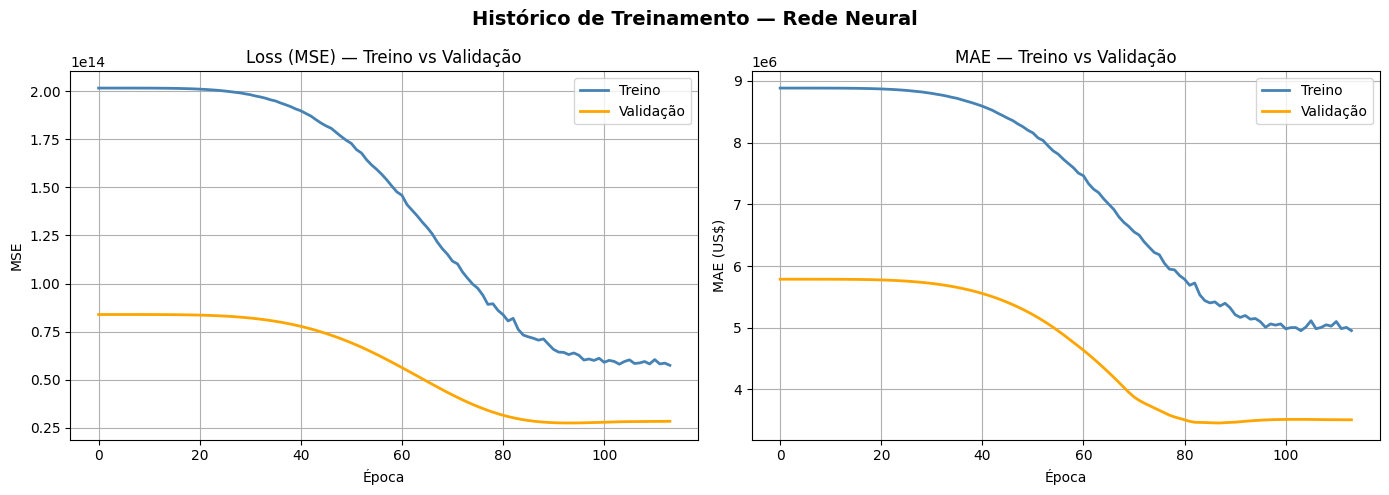

✅ Gráfico de histórico gerado!


In [14]:
# ============================================================
# Célula 6: Visualização do Histórico de Treinamento
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Histórico de Treinamento — Rede Neural",
             fontsize=14, fontweight="bold")

# --------------------------------------------------------
# Gráfico 1: Loss (MSE) — Treino vs Validação
# --------------------------------------------------------
axes[0].plot(historico.history["loss"],
             label="Treino", color="steelblue", linewidth=2)
axes[0].plot(historico.history["val_loss"],
             label="Validação", color="orange", linewidth=2)
axes[0].set_title("Loss (MSE) — Treino vs Validação")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("MSE")
axes[0].legend()
axes[0].grid(True)

# --------------------------------------------------------
# Gráfico 2: MAE — Treino vs Validação
# --------------------------------------------------------
axes[1].plot(historico.history["mae"],
             label="Treino", color="steelblue", linewidth=2)
axes[1].plot(historico.history["val_mae"],
             label="Validação", color="orange", linewidth=2)
axes[1].set_title("MAE — Treino vs Validação")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("MAE (US$)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("grafico_historico_treino.png", dpi=120)
plt.show()
plt.close()
print("✅ Gráfico de histórico gerado!")

## Fase 6: Avaliação e Comparativo dos Modelos

Avaliamos a Rede Neural no conjunto de teste e comparamos
com os modelos do Módulo 1:

**Métricas utilizadas:**
- **MAE:** erro médio em dólares — fácil interpretação
- **RMSE:** penaliza erros grandes — critério de desempate
- **R²:** percentual da variação explicada pelo modelo

In [20]:
# ============================================================
# Célula 7: Avaliação e Comparativo dos Modelos
# ============================================================

# Predições da Rede Neural
y_pred_rn = modelo_rn.predict(X_test_scaled).flatten()

# Métricas da Rede Neural
mae_rn  = mean_absolute_error(y_test, y_pred_rn)
mse_rn  = mean_squared_error(y_test, y_pred_rn)
rmse_rn = np.sqrt(mse_rn)
r2_rn   = r2_score(y_test, y_pred_rn)

print("=== AVALIAÇÃO DA REDE NEURAL ===")
print("-" * 45)
print(f"  MAE  : US$ {mae_rn:,.2f}")
print(f"  MSE  : US$ {mse_rn:,.2f}")
print(f"  RMSE : US$ {rmse_rn:,.2f}")
print(f"  R²   : {r2_rn:.4f}")
print("-" * 45)

# --------------------------------------------------------
# Comparativo com modelos anteriores
# --------------------------------------------------------
print("\n=== COMPARATIVO DOS MODELOS ===")
print("-" * 65)
print(f"  {'Modelo':<25} {'MAE':>15} {'RMSE':>15} {'R²':>8}")
print("-" * 65)
print(f"  {'Regressão Linear':<25} US$ {'4,921,851':>9} US$ {'6,371,145':>9} {'0.6943':>8}")
print(f"  {'KNN (K=10)':<25} US$ {'6,115,353':>9} US$ {'6,115,353':>9} {'0.7183':>8}")
print(f"  {'Rede Neural':<25} US$ {mae_rn:>12,.0f} US${rmse_rn:>12,.0f} {r2_rn:>8.4f}")
print("-" * 65)

# Modelo campeão
modelos = {
    "Regressão Linear": 6371145,
    "KNN K=10"        : 6115353,
    "Rede Neural"     : rmse_rn
}
campeao = min(modelos, key=modelos.get)
print(f"\n🏆 Modelo campeão: {campeao}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
=== AVALIAÇÃO DA REDE NEURAL ===
---------------------------------------------
  MAE  : US$ 4,038,354.75
  MSE  : US$ 36,918,943,285,248.00
  RMSE : US$ 6,076,096.06
  R²   : 0.7219
---------------------------------------------

=== COMPARATIVO DOS MODELOS ===
-----------------------------------------------------------------
  Modelo                                MAE            RMSE       R²
-----------------------------------------------------------------
  Regressão Linear          US$ 4,921,851 US$ 6,371,145   0.6943
  KNN (K=10)                US$ 6,115,353 US$ 6,115,353   0.7183
  Rede Neural               US$    4,038,355 US$   6,076,096   0.7219
-----------------------------------------------------------------

🏆 Modelo campeão: Rede Neural


## Fase 7: Serialização do Modelo

Retreinamos o modelo campeão na base completa (treino + teste)
para maximizar o aprendizado antes de serializar.

**Arquivos salvos:**
- `modelo_rn_v2.keras` — modelo Keras no formato nativo
- `pipeline_scaler.pkl` — pipeline de pré-processamento
- `label_encoder.pkl` — encoder das posições
- `metricas_v2.json` — métricas e metadados do modelo

**Por que formato .keras ao invés de .pkl?**
O formato nativo do Keras preserva a arquitetura completa,
os pesos e a configuração do otimizador, mais seguro
e portátil que serializar com joblib.

In [15]:
# ============================================================
# Célula 8: Serialização do Modelo Campeão
# ============================================================

# --------------------------------------------------------
# Retreinando na base completa (treino + validação)
# Agora que o modelo foi validado usamos todos os dados
# de treino para maximizar o aprendizado
# --------------------------------------------------------
print("=== RETREINANDO NA BASE COMPLETA ===")
print("-" * 45)

# Recriando o modelo com a mesma arquitetura
modelo_final = criar_modelo_rn(input_dim=X_train_scaled.shape[1])

# Retreinando com todos os dados de treino
historico_final = modelo_final.fit(
    X_train_scaled, y_train,
    epochs=121,              # mesmo número de épocas do melhor modelo
    batch_size=32,
    verbose=0                # sem output para ficar mais limpo
)
print(f"✅ Modelo retreinado com {len(X_train_scaled)} registros")

# --------------------------------------------------------
# Salvando o modelo no formato nativo do Keras
# --------------------------------------------------------
os.makedirs("models", exist_ok=True)
modelo_final.save("models/modelo_rn_v2.keras")
print("✅ Modelo salvo em models/modelo_rn_v2.keras")

# --------------------------------------------------------
# Salvando o pipeline de pré-processamento
# --------------------------------------------------------
joblib.dump(pipeline_scaler, "models/pipeline_scaler.pkl")
print("✅ Pipeline salvo em models/pipeline_scaler.pkl")

# --------------------------------------------------------
# Salvando o LabelEncoder
# --------------------------------------------------------
joblib.dump(le, "models/label_encoder.pkl")
print("✅ LabelEncoder salvo em models/label_encoder.pkl")

# --------------------------------------------------------
# Salvando as métricas em JSON
# --------------------------------------------------------
metricas_v2 = {
    "modelo"              : "Rede Neural (Keras)",
    "versao"              : "v2",
    "data_treinamento"    : datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "dataset"             : "NBA Players Stats and Salaries 2022-23",
    "n_registros"         : len(df_processado),
    "arquitetura"         : "128-64-32-1 (ReLU + Dropout 20%)",
    "epochs_treinadas"    : 121,
    "batch_size"          : 32,
    "optimizer"           : "adam",
    "variaveis_preditoras": X.columns.tolist(),
    "comparativo_modelos" : {
        "Regressao_Linear": {"MAE": 4921851, "RMSE": 6371145, "R2": 0.6943},
        "KNN_K10"         : {"MAE": 6115353, "RMSE": 6115353, "R2": 0.7183},
        "Rede_Neural"     : {
            "MAE" : round(mae_rn, 2),
            "RMSE": round(rmse_rn, 2),
            "R2"  : round(r2_rn, 4)
        }
    },
    "metricas_teste": {
        "MAE" : round(mae_rn, 2),
        "MSE" : round(mse_rn, 2),
        "RMSE": round(rmse_rn, 2),
        "R2"  : round(r2_rn, 4)
    }
}

with open("models/metricas_v2.json", "w", encoding="utf-8") as f:
    json.dump(metricas_v2, f, indent=2, ensure_ascii=False)
print("✅ Métricas salvas em models/metricas_v2.json")

# Confirmando
with open("models/metricas_v2.json", encoding="utf-8") as f:
    lido = json.load(f)
print("\n📄 Métricas registradas:")
print(json.dumps(lido, indent=2, ensure_ascii=False))

=== RETREINANDO NA BASE COMPLETA ===
---------------------------------------------
✅ Modelo retreinado com 373 registros
✅ Modelo salvo em models/modelo_rn_v2.keras
✅ Pipeline salvo em models/pipeline_scaler.pkl
✅ LabelEncoder salvo em models/label_encoder.pkl
✅ Métricas salvas em models/metricas_v2.json

📄 Métricas registradas:
{
  "modelo": "Rede Neural (Keras)",
  "versao": "v2",
  "data_treinamento": "2026-10-21 23:10:31",
  "dataset": "NBA Players Stats and Salaries 2022-23",
  "n_registros": 467,
  "arquitetura": "128-64-32-1 (ReLU + Dropout 20%)",
  "epochs_treinadas": 121,
  "batch_size": 32,
  "optimizer": "adam",
  "variaveis_preditoras": [
    "Position",
    "Age",
    "GP",
    "GS",
    "3P",
    "TRB",
    "AST",
    "STL",
    "BLK",
    "PF",
    "PTS",
    "PER",
    "TS%",
    "3PAr",
    "FTr",
    "ORB%",
    "TRB%",
    "STL%",
    "BLK%",
    "TOV%",
    "USG%",
    "WS",
    "tier_time",
    "eficiencia"
  ],
  "comparativo_modelos": {
    "Regressao_Linear": {
